In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [49]:
units = pd.read_csv('units_L234.csv').copy()

In [50]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [51]:
units_cleaned = clean_dataset(units)

In [52]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [53]:
E_L23 = units_cleaned[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [54]:
len(E_L23), len(I_L23), len(E_L4), len(I_L4)

(13157, 1299, 9487, 828)

In [55]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

# Connection Probability vs Inter-Somatic Distance

In [56]:
def existing_connections(
    path_name, pre_pop, post_pop,
    syn, metric='Euclidean'
):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if metric == 'Euclidean':
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if metric == 'Euclidean':
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    return conn

In [57]:
def potential_connections(pre_pop, post_pop, metric='Euclidean'):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if metric == 'Euclidean':
        feat_to_keep.append('pt_position_y')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # --- cartesian product --- all_pairs = pre.merge(postn how='cross') probably easier ;D
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # --- rimuove self-connections ---
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    # --- distanze riga per riga ---
    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if metric == 'Euclidean':
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    all_pairs['size'] = 0.0

    return all_pairs

In [58]:
def compute_connection_probability(conn, pot, value_column, bins):
    syn_counts, _ = np.histogram(conn[value_column], bins=bins)
    pot_counts, _ = np.histogram(pot[value_column], bins=bins)

    prob = np.divide(
        syn_counts, pot_counts,
        out=np.zeros_like(syn_counts, dtype=float),
        where=pot_counts != 0
    )

    # Binomial SEM
    sem_prob = np.sqrt(prob * (1 - prob) / pot_counts)
    sem_prob[pot_counts == 0] = np.nan

    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    return bin_centers, prob, sem_prob

In [59]:
res = {}

dist_bins = np.linspace(0, 400, 10)

for path, pre, post in pathways:
    conn = existing_connections(path, pre, post, synapses, metric='Euclidean')
    pot = potential_connections(pre, post, metric='Euclidean')

    c, p, s = compute_connection_probability(conn, pot, 'euclidean', dist_bins)
    res[path] = (c, p, s)

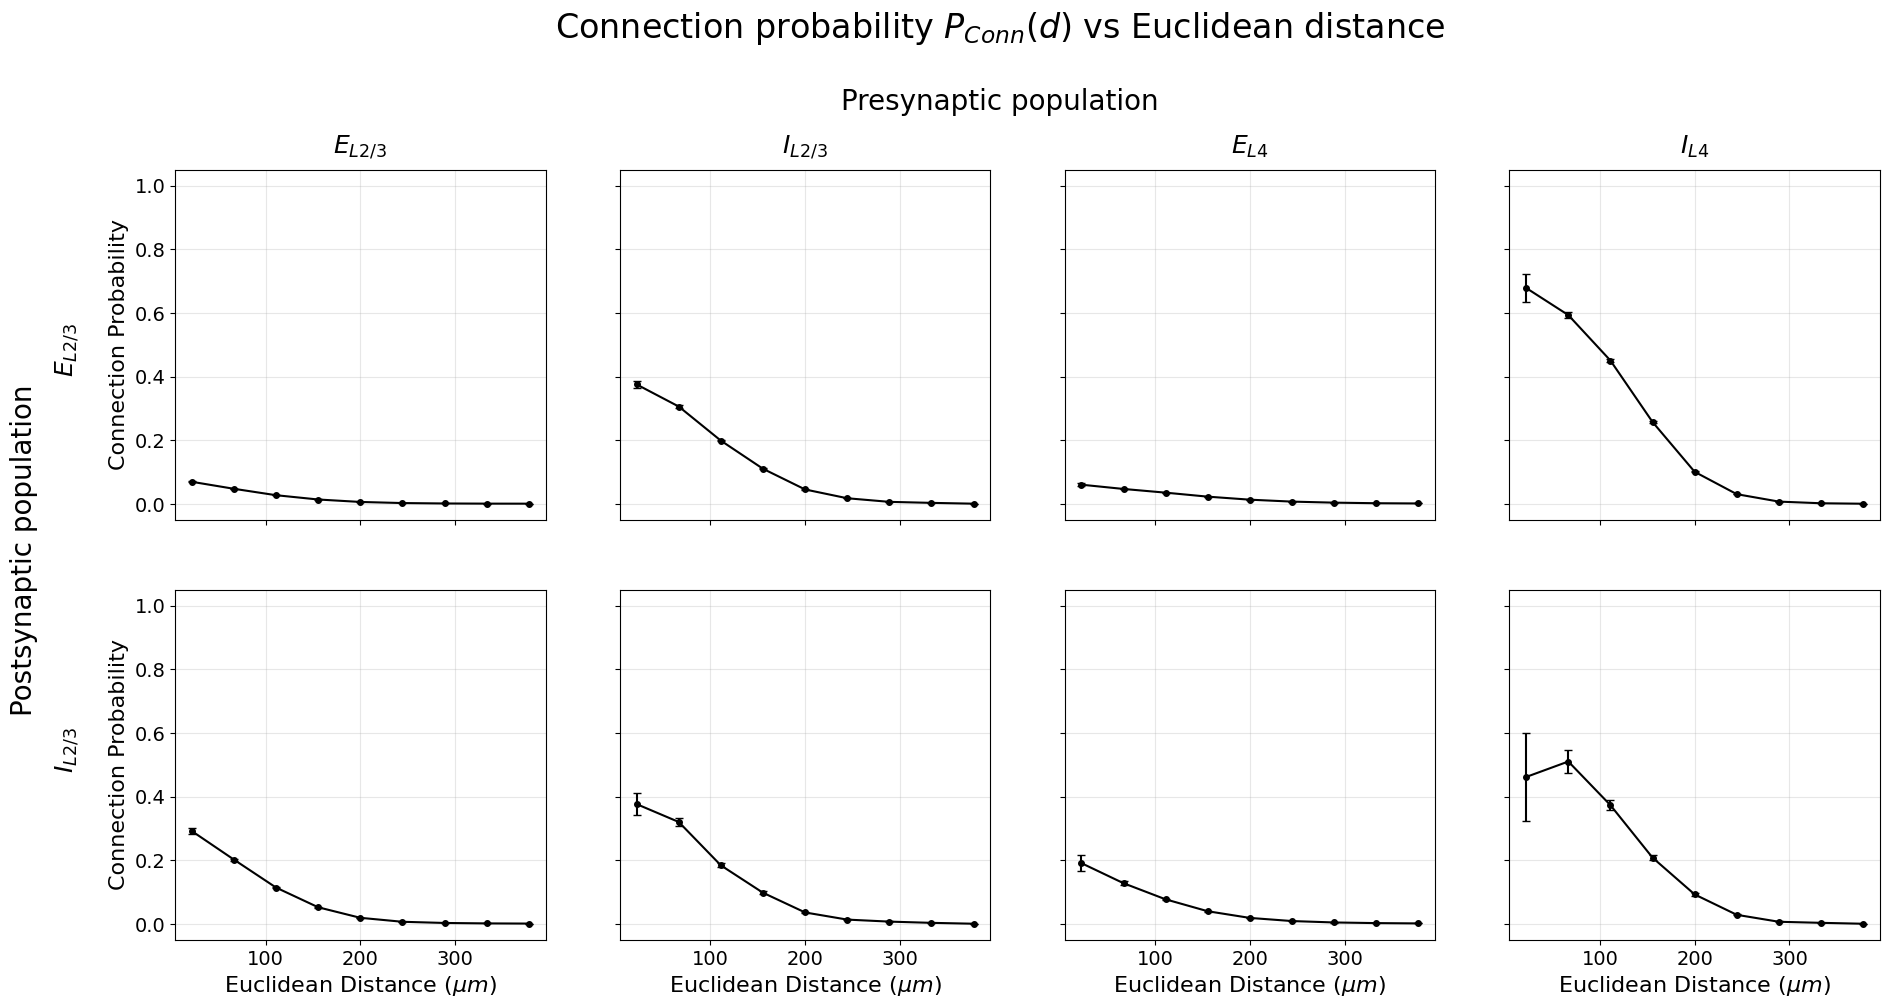

In [60]:
fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)

# -----------------------
# plotting
# -----------------------
for i, (path, prob) in enumerate(res.items()):
    row = i // 4
    col = i % 4

    centers_emp, prob_emp, sem_emp = prob

    axs[row, col].errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=4,
        linewidth=1.5,
        capsize=3
    )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')
    axs[row, col].set_ylim(-0.05, 1.05)

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Connection Probability", fontsize=16)
axs[1, 0].set_ylabel("Connection Probability", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Connection probability $P_{Conn}(d)$ vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_Euclidean.png", dpi=300)
plt.show()

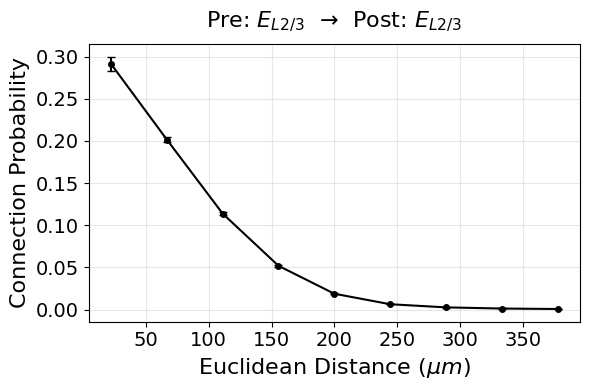

In [61]:
first_key = list(res.keys())[4]
centers_emp, prob_emp, sem_emp = res[first_key]

fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(
    centers_emp,
    prob_emp,
    yerr=sem_emp,
    color='black',
    linestyle='-',
    marker='o',
    markersize=4,
    linewidth=1.5,
    capsize=3
)

ax.grid(alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.set_facecolor('white')
#ax.set_ylim(-0.05, 1.05)

ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)
ax.set_ylabel("Connection Probability", fontsize=16)

ax.set_title(
    r"Pre: $E_{L2/3}$  →  Post: $E_{L2/3}$", # E_{L2/3} -> I_{L2/3} instead look at pathways
    fontsize=16, pad=12
)

plt.tight_layout()
plt.show()

# Synaptic Volume vs Inter-Somatic Distance

In [62]:
from scipy.stats import sem


def make_syn_df(values, feature_name, sizes):
    df = pd.DataFrame({feature_name: values, 'size': sizes})
    return df.copy()


def compute_synapse_size_statistics(paired_df, value_column, bins):
    """
    Computes mean synapse size and SEM across binned feature values.

    Parameters:
        paired_df (DataFrame): Contains actual synapses with 'size' column.
        value_column (str): Feature used for binning.
        bins (np.array): Bin edges.

    Returns:
        bin_centers, mean_size, sem_size
    """
    mean_size = []
    sem_size = []

    for i in range(len(bins) - 1):
        in_bin = (paired_df[value_column] >= bins[i]) & (paired_df[value_column] < bins[i + 1])
        sizes = paired_df.loc[in_bin, 'size']
        mean_size.append(sizes.mean() if not sizes.empty else 0)
        sem_size.append(sem(sizes) if not sizes.empty else np.nan)

    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    return bin_centers, mean_size, sem_size

In [63]:
emp_dict = {}
emp_size_euc = {}

for path, pre, post in pathways:

    conn = existing_connections(path, pre, post, synapses)
    pot = potential_connections(pre, post)

    den = pd.concat([conn, pot], ignore_index=True)

    emp_dict[path] = den

for path, connection in emp_dict.items():

    if connection.empty:
        print(f"Skipping {path} (empty empirical data)")
        continue

    cols = ["euclidean", "size"]
    if not all(col in connection.columns for col in cols):
        print(f"Missing columns in {path}, skipping.")
        continue

    mask_syn = connection["size"] > 0
    if not mask_syn.any():
        print(f"No synapses found in empirical {path}, skipping.")
        continue

    syn = connection.loc[mask_syn, cols].reset_index(drop=True)

    # --- Euclidean ---
    df_euc = make_syn_df(syn["euclidean"], "euclidean", syn["size"])
    c, m, s = compute_synapse_size_statistics(df_euc, "euclidean", dist_bins)
    emp_size_euc[path] = (c, np.array(m), np.array(s))

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_39920\2939014861.py:28: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sem_size.append(sem(sizes) if not sizes.empty else np.nan)
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_39920\2939014861.py:28: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sem_size.append(sem(sizes) if not sizes.empty else np.nan)


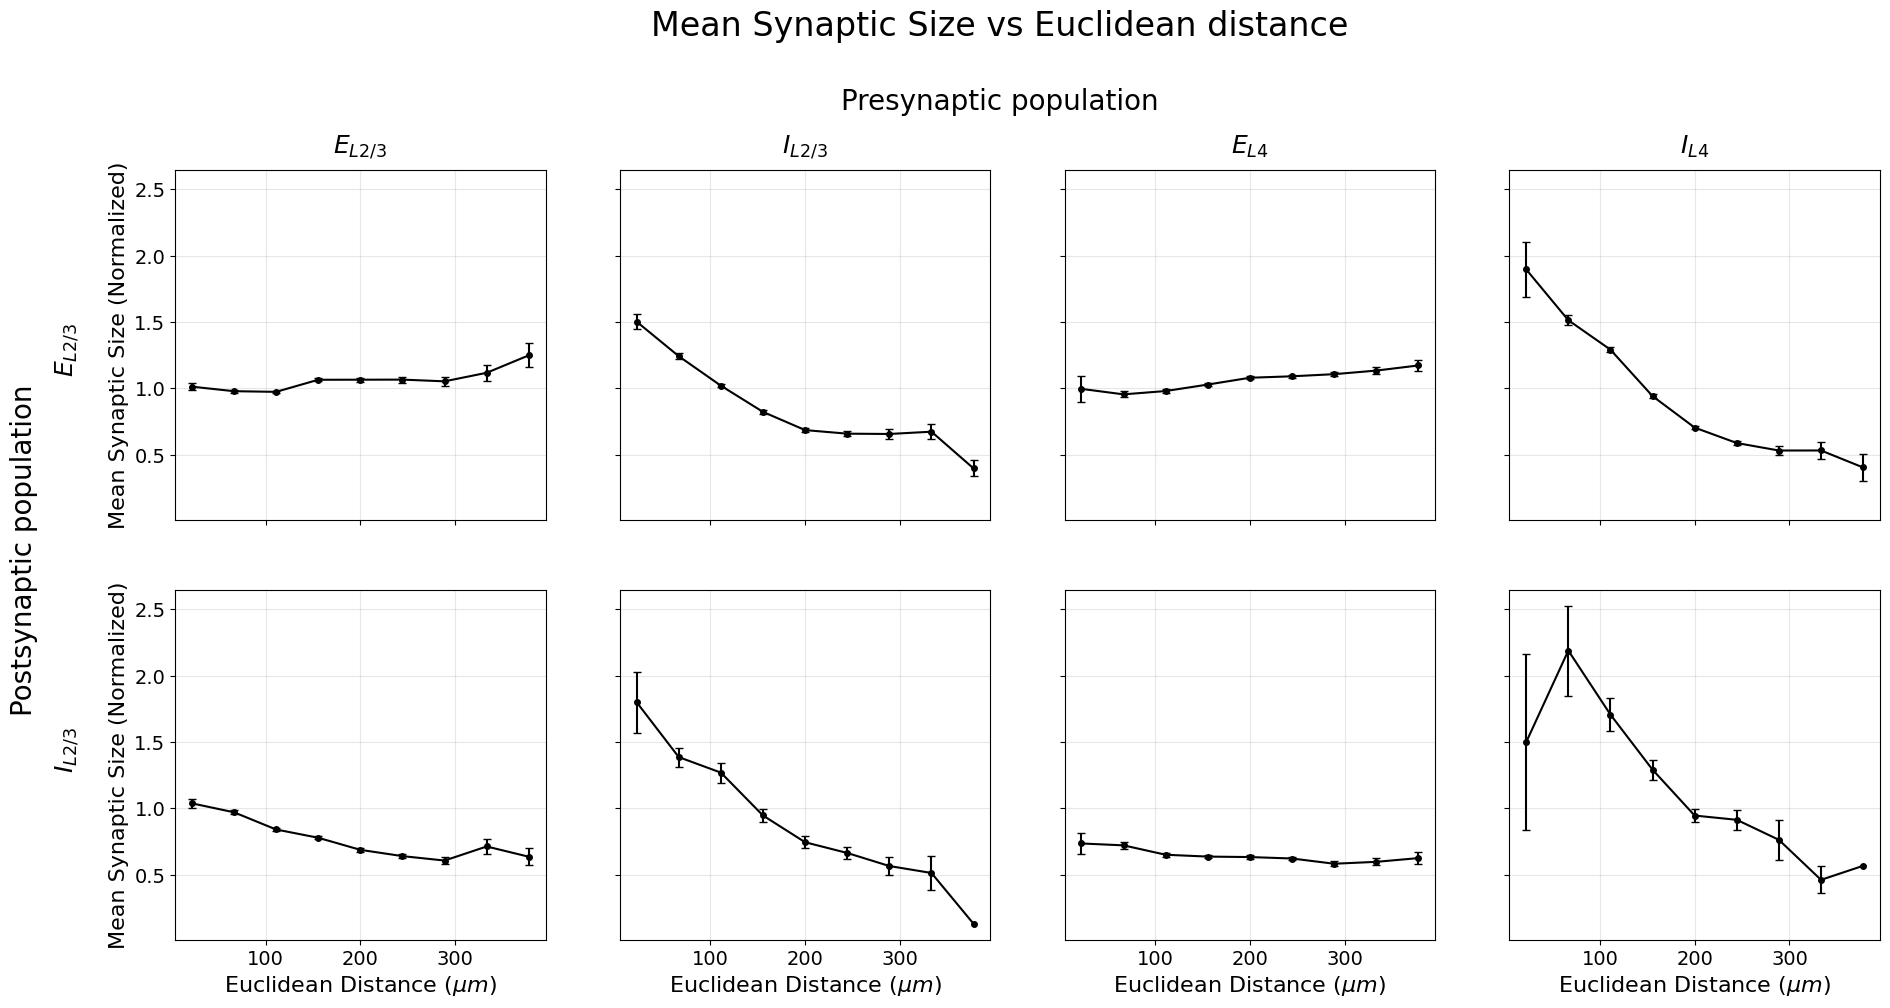

In [64]:
fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)

# -----------------------
# plotting
# -----------------------
for i, (path, prob) in enumerate(emp_size_euc.items()):
    row = i // 4
    col = i % 4

    centers_emp, prob_emp, sem_emp = prob

    axs[row, col].errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=4,
        linewidth=1.5,
        capsize=3
    )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Mean Synaptic Size (Normalized)", fontsize=16)
axs[1, 0].set_ylabel("Mean Synaptic Size (Normalized)", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Mean Synaptic Size vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()

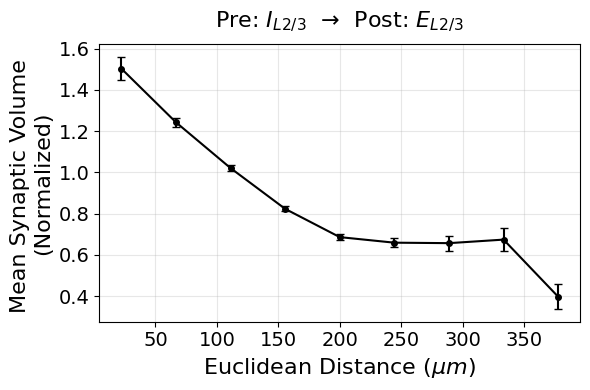

In [65]:
first_key = list(emp_size_euc.keys())[1]
centers_emp, prob_emp, sem_emp = emp_size_euc[first_key]

fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(
    centers_emp,
    prob_emp,
    yerr=sem_emp,
    color='black',
    linestyle='-',
    marker='o',
    markersize=4,
    linewidth=1.5,
    capsize=3
)

ax.grid(alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.set_facecolor('white')

ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)
ax.set_ylabel("Mean Synaptic Volume \n(Normalized)", fontsize=16)

ax.set_title(
    r"Pre: $I_{L2/3}$  →  Post: $E_{L2/3}$",
    fontsize=16, pad=12
)

plt.tight_layout()
plt.savefig("size_1.png", dpi=500)
plt.show()

# Connection Probability vs Preferred Orientation Difference

In [66]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [67]:
def existing_connections(
    path_name, pre_pop, post_pop,
    syn, metric='Ori_Diff'
):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    mask_sel_pre = pre_pop['selective_ori'] == 'True'
    mask_sel_post = post_pop['selective_ori'] == 'True'

    pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
    post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pref_ori_fit',
    ]

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns = lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns = lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    ori_pre = conn['pre_pref_ori_fit'].to_numpy()
    ori_post = conn['post_pref_ori_fit'].to_numpy()

    conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)

    return conn

In [68]:
def potential_connections(pre_pop, post_pop):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    mask_sel_pre = pre_pop['selective_ori'] == 'True'
    mask_sel_post = post_pop['selective_ori'] == 'True'

    pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
    post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

    feat_to_keep = ['pt_root_id', 'pref_ori_fit']

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    # Compute orientation difference row-wise
    ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
    ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

    all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)

    return all_pairs

In [69]:
pathways = [
    ('E23_E23', E_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [70]:
res = {}

ori_bins = np.linspace(-np.pi/2, np.pi/2, 10)

for path, pre, post in pathways:
    conn = existing_connections(path, pre, post, synapses)
    pot = potential_connections(pre, post)

    c, p, s = compute_connection_probability(conn, pot, 'ori_diff', ori_bins)
    res[path] = (c, p, s)

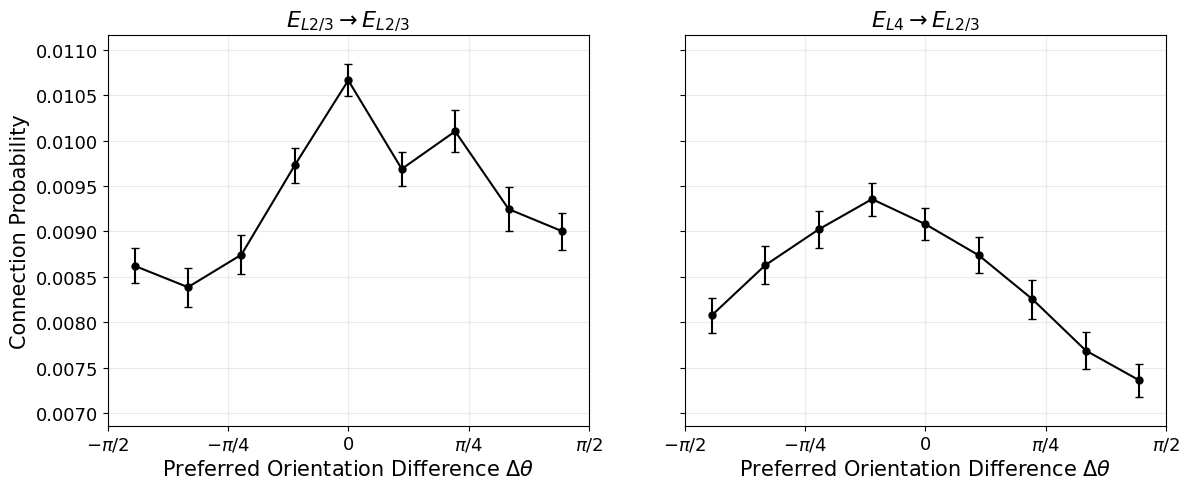

In [71]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (path, prob) in zip(axs, res.items()):

    centers_emp, prob_emp, sem_emp = prob

    ax.errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=5,
        linewidth=1.5,
        capsize=3
    )

    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=13)
    ax.set_facecolor('white')

    ax.set_xlim(-np.pi/2, np.pi/2)
    ax.set_xticks(
        [-np.pi/2, -np.pi/4, 0, np.pi/4, np.pi/2]
    )
    ax.set_xticklabels(
        [r"$-\pi/2$", r"$-\pi/4$", r"$0$", r"$\pi/4$", r"$\pi/2$"]
    )

all_probs = np.concatenate([res[k][1] for k in res])
ymin = all_probs.min()
ymax = all_probs.max()

margin = 0.0005
axs[0].set_ylim(ymin - margin, ymax + margin)

# ---- labels
axs[0].set_ylabel("Connection Probability", fontsize=15)

for ax in axs:
    ax.set_xlabel(r"Preferred Orientation Difference $\Delta\theta$", fontsize=15)

# ---- titles
axs[0].set_title(r"$E_{L2/3} \rightarrow E_{L2/3}$", fontsize=16)
axs[1].set_title(r"$E_{L4} \rightarrow E_{L2/3}$", fontsize=16)


plt.tight_layout()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_OriDiff_clean.png", dpi=300)
plt.show()

# Synaptic Volume vs Preferred Orientation Difference

In [72]:
emp_dict = {}
emp_size_euc = {}

for path, pre, post in pathways:

    conn = existing_connections(path, pre, post, synapses)
    pot = potential_connections(pre, post)

    den = pd.concat([conn, pot], ignore_index=True)

    emp_dict[path] = den

for path, connection in emp_dict.items():

    if connection.empty:
        print(f"Skipping {path} (empty empirical data)")
        continue

    cols = ["ori_diff", "size"]
    if not all(col in connection.columns for col in cols):
        print(f"Missing columns in {path}, skipping.")
        continue

    mask_syn = connection["size"] > 0
    if not mask_syn.any():
        print(f"No synapses found in empirical {path}, skipping.")
        continue

    syn = connection.loc[mask_syn, cols].reset_index(drop=True)

    # --- Euclidean ---
    df_ori = make_syn_df(syn["ori_diff"], "ori_diff", syn["size"])
    c, m, s = compute_synapse_size_statistics(df_ori, "ori_diff", ori_bins)
    emp_size_euc[path] = (c, np.array(m), np.array(s))

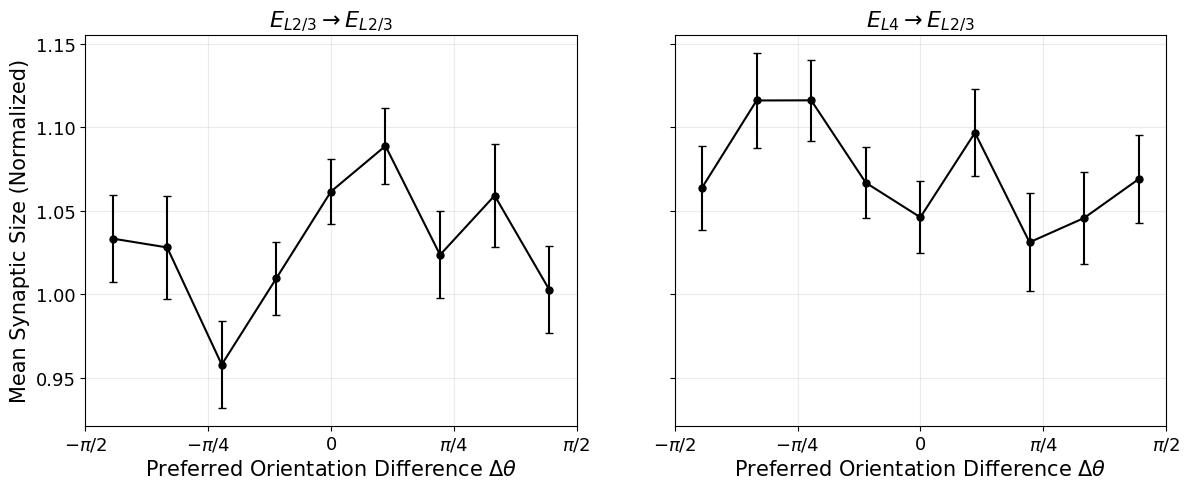

In [73]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (path, prob) in zip(axs, emp_size_euc.items()):

    centers_emp, prob_emp, sem_emp = prob

    ax.errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=5,
        linewidth=1.5,
        capsize=3
    )

    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=13)
    ax.set_facecolor('white')

    ax.set_xlim(-np.pi/2, np.pi/2)
    ax.set_xticks(
        [-np.pi/2, -np.pi/4, 0, np.pi/4, np.pi/2]
    )
    ax.set_xticklabels(
        [r"$-\pi/2$", r"$-\pi/4$", r"$0$", r"$\pi/4$", r"$\pi/2$"]
    )

# ---- labels
axs[0].set_ylabel("Mean Synaptic Size (Normalized)", fontsize=15)

for ax in axs:
    ax.set_xlabel(r"Preferred Orientation Difference $\Delta\theta$", fontsize=15)

# ---- titles
axs[0].set_title(r"$E_{L2/3} \rightarrow E_{L2/3}$", fontsize=16)
axs[1].set_title(r"$E_{L4} \rightarrow E_{L2/3}$", fontsize=16)


plt.tight_layout()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_OriDiff.png", dpi=300)
plt.show()